<a href="https://colab.research.google.com/github/Dharmaamerta/data-visualtization/blob/main/2618904_Data_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## **DATA VISUALIZATION**

**RESERVASI HOTEL**

**Import lib**

In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Membaca Dataset**

In [ ]:
file_path = '/content/drive/MyDrive/Itn/Data minning/Data_150.xlsx'
df = pd.read_excel(file_path, engine='openpyxl')

**Mencetak data dari google drive**

In [ ]:
print(df)

      No ID Reservasi         Nama Tamu Jenis Kelamin  Umur Tipe Kamar  \
0      1       RSV001      Andi Pratama     Laki-laki  25.0     Deluxe   
1      2       RSV002      Budi Santoso     Laki-laki  31.0     Deluxe   
2      3       RSV003     Citra Lestari     Perempuan  24.0      Suite   
3      4       RSV004         Dinda Ayu     Perempuan  28.0   Standard   
4      5       RSV005       Eko Saputra     Laki-laki  35.0     Deluxe   
..   ...          ...               ...           ...   ...        ...   
145  146       RSV146    Surya Prasetyo     Laki-laki  19.0     Deluxe   
146  147       RSV147  Farhan Anggraini     Laki-laki  49.0     Deluxe   
147  148       RSV148    Salsa Fadillah     Perempuan  26.0   Standard   
148  149       RSV149   Octavia Nugroho     Perempuan  35.0     Deluxe   
149  150       RSV150     Hasan Susanto     Laki-laki  34.0   Standard   

    Tanggal Check-in Tanggal Check-out  Lama Menginap  Harga/Malam  \
0         2026-01-04        2026-01-06   

**Melihat struktur Dataset**

In [ ]:
print("Ukuran Data set:",df.shape)
print("\nNama kolom:",df.columns.tolist())
print("\nTipe data:")
print(df.dtypes)


Ukuran Data set: (150, 13)

Nama kolom: ['No', 'ID Reservasi', 'Nama Tamu', 'Jenis Kelamin', 'Umur', 'Tipe Kamar', 'Tanggal Check-in', 'Tanggal Check-out', 'Lama Menginap', 'Harga/Malam', 'Metode Pembayaran', 'Status Reservasi', 'Meotde Pembayaran']

Tipe data:
No                            int64
ID Reservasi                 object
Nama Tamu                    object
Jenis Kelamin                object
Umur                        float64
Tipe Kamar                   object
Tanggal Check-in     datetime64[ns]
Tanggal Check-out    datetime64[ns]
Lama Menginap                 int64
Harga/Malam                   int64
Metode Pembayaran            object
Status Reservasi             object
Meotde Pembayaran            object
dtype: object


**Menambahkan kolom Check-In_Month**

In [ ]:
df['Tanggal Check-in'] = pd.to_datetime(df['Tanggal Check-in'], errors='coerce')
df['checkin_month'] = df['Tanggal Check-in'].dt.strftime('%Y-%m')

print("Tanggal gagal dibaca:", df['Tanggal Check-in'].isnull().sum())
print(df[['Tanggal Check-in', 'checkin_month']].head())

Tanggal gagal dibaca: 0
  Tanggal Check-in checkin_month
0       2026-01-04       2026-01
1       2026-01-03       2026-01
2       2026-01-05       2026-01
3       2026-01-08       2026-01
4       2026-01-10       2026-01


**Menambahkan kolom GMV Pada Dataset**

In [ ]:
df['gmv'] = df['Harga/Malam'] * df['Lama Menginap']


**Agregasi Dataset / PENGELOMPOKAN DATA**

In [ ]:
monthly_amount = df.groupby('checkin_month')['gmv'].sum().reset_index()
print(monthly_amount)

  checkin_month       gmv
0       2026-01  20300000
1       2026-02  15800000
2       2026-03  21950000
3       2026-04  18400000
4       2026-05  18600000
5       2026-06  16300000
6       2026-07  20550000
7       2026-08  23400000
8       2026-09  17650000
9       2026-10   1050000


**Membuat line chart Trend Pertumbuhan GMV**

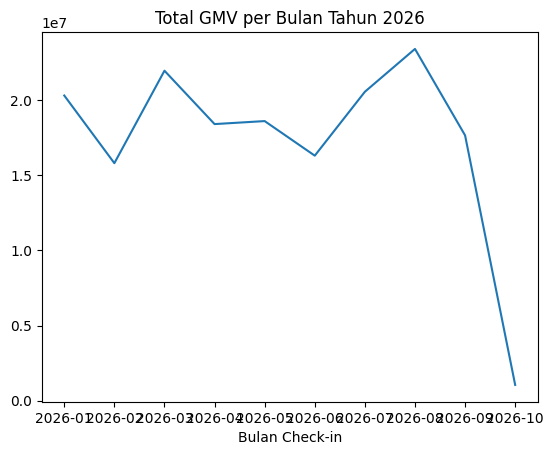

In [ ]:
import matplotlib.pyplot as plt

plt.plot(monthly_amount['checkin_month'], monthly_amount['gmv'])
plt.title('Total GMV per Bulan Tahun 2026')
plt.xlabel('Bulan Check-in')
plt.show()

**Membuat Figure**

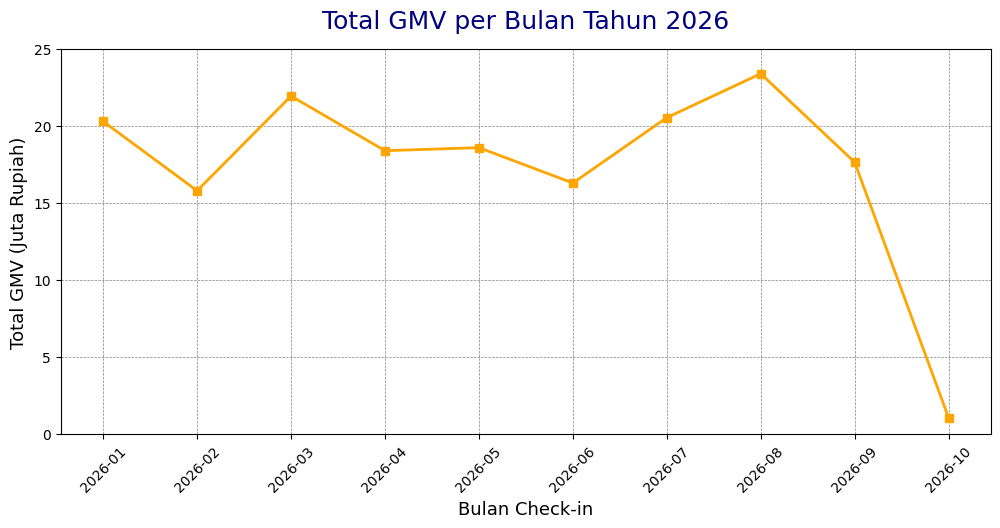

In [ ]:
#Membuat figure size
plt.figure(figsize=(12, 5))
plt.plot(monthly_amount['checkin_month'], monthly_amount['gmv'],
         color='orange', marker='s', linestyle='-', linewidth=2)

plt.title('Total GMV per Bulan Tahun 2026', fontsize=18, pad=15, color='navy')

#Menambahkan Title dan Axis Labels dan mengatur tampilan grafik sumbu x dan sumbu y)
plt.xlabel('Bulan Check-in', fontsize=13)
plt.ylabel('Total GMV (Juta Rupiah)', fontsize=13)
plt.xticks(rotation=45)
plt.grid(color='gray', linestyle='--', linewidth=0.5)
plt.ylim(ymin=0)
nilai, posisi = plt.yticks()
plt.yticks(nilai, (nilai / 1000000).astype(int))


plt.show()